### Homework 07 - Least-squares method
Igor Di Tota

**Introduction**

In this exercise a set of $N$ measurements $(x_i, y_i, \sigma_i)$ is described with a polynomial series
$$
\mu(x; \mathbf{a}) = \sum_{k=0}^{M} a_k\, x^k ,
$$
where $M$ is the order of the polynomial and $\mathbf{a} = (a_0, \dots, a_M)$ are the $M+1$ free parameters.

Since the model is linear in the parameters, the least-squares method gives the best estimates of $\mathbf{a}$ and their covariance matrix, by solving a system of linear equations.

Assuming Gaussian measurement uncertainties and a correct model, the value of $\chi^2$ at the minimum follows a $\chi^2$ distribution with $N_{df} = N - (M+1)$ degrees of freedom, so it can be used to test whether the polynomial of order $M$ is consistent with the data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import os
os.makedirs("images", exist_ok=True)

# Data: x_i, y_i, sigma_i
x, y, sigma = np.loadtxt("07_homework.dat", unpack=True)
N = y.size

print(f"Number of points: N = {N}")
print(f"x range:     [{x.min():.4f}, {x.max():.4f}]")
print(f"sigma range: [{sigma.min():.4f}, {sigma.max():.4f}]")
print(f"sigma increasing with x: {np.all(np.diff(sigma) > 0)}")

Number of points: N = 24
x range:     [0.0250, 1.1750]
sigma range: [0.0207, 0.0498]
sigma increasing with x: True


### Data

The data set consists of $N = 24$ points. Each value $y_i$ is given with its uncertainty $\sigma_i$, which is not constant but increases with $x$, from about $0.021$ to $0.050$.
The measurements therefore have different weights in the fit, and each term of the $\chi^2$ must be divided by its own $\sigma_i^2$.

The dependence of $y$ on $x$ is clearly not linear. No model for this dependence is given, so polynomials of increasing order are tested.

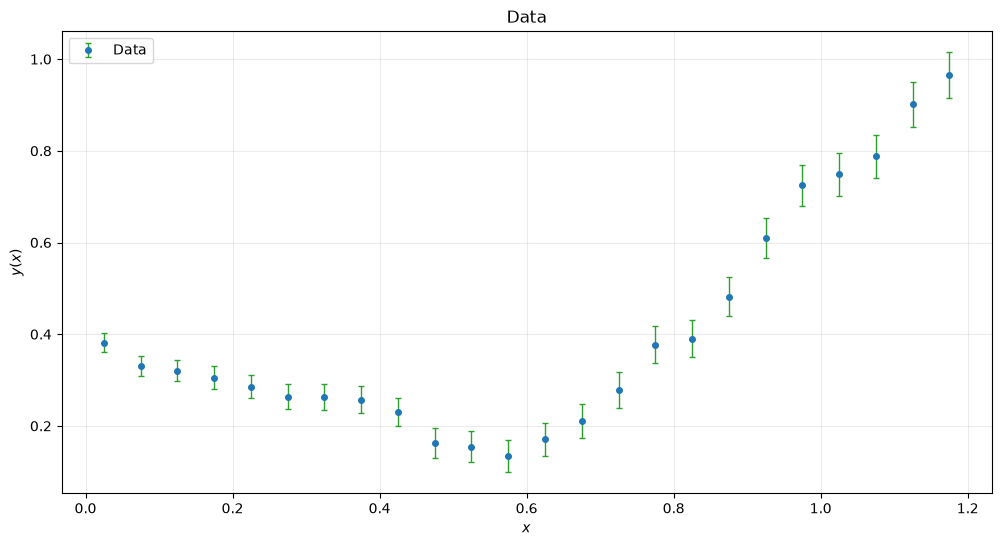

In [2]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.errorbar(x, y, yerr=sigma, fmt="o", ms=4, capsize=2, color="tab:blue", ecolor="tab:green", elinewidth=1, label="Data")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y(x)$")
ax.set_title("Data")
ax.legend()
ax.grid(alpha=0.3, color="silver")
fig.savefig("images/data.pdf", bbox_inches="tight")
plt.show()


### Linear regression

The model is linear in the parameters:
$$
\mu(x; \mathbf{a}) = \sum_{k=0}^{M} a_k f_k(x) \quad \text{with } f_k(x) = x^k.
$$
The best estimates of $\mathbf{a}$ correspond to the minimum of
$$
\chi^2(\mathbf{a}) = \sum_{i=1}^{N} \frac{\left(y_i - \sum_{k} a_k f_k(x_i)\right)^2}{\sigma_i^2} ,
$$
which, for Gaussian uncertainties, is equivalent to the maximum of the log-likelihood function $\ell = \ln L$, since $\chi^2 = -2\ell$.

Setting $\partial\chi^2/\partial a_l = 0$ for $l = 0, \dots, M$ gives a system of $M+1$ linear equations
$$
\sum_{k=0}^{M} \left( \sum_{i=1}^{N} \frac{f_l(x_i)\, f_k(x_i)}{\sigma_i^2} \right) a_k = \sum_{i=1}^{N} \frac{f_l(x_i)\, y_i}{\sigma_i^2} ,
$$
which can be written in matrix form as $\mathbb{A}\cdot\mathbf{a} = \mathbf{b}$, with
$$
\mathbb{A}_{lk} = \sum_{i=1}^{N} \frac{x_i^{\,l+k}}{\sigma_i^2} ,
\qquad
b_l = \sum_{i=1}^{N} \frac{x_i^{\,l}\, y_i}{\sigma_i^2} ,
\qquad
\mathbf{a} = \mathbb{A}^{-1} \cdot \mathbf{b} .
$$

The first derivatives of the $\chi^2$ are
$$
\frac{\partial\chi^2}{\partial a_l} = -2 \sum_{i=1}^{N} \frac{f_l(x_i)}{\sigma_i^2} \left( y_i - \sum_{k=0}^{M} a_k f_k(x_i) \right) ,
$$
and differentiating once more with respect to $a_k$,
$$
\frac{\partial^2\chi^2}{\partial a_l\, \partial a_k} = 2 \sum_{i=1}^{N} \frac{f_l(x_i)\, f_k(x_i)}{\sigma_i^2} = 2\,\mathbb{A}_{lk} .
$$
The second derivatives do not depend on $\mathbf{a}$: the $\chi^2$ is exactly a quadratic function of the parameters, so the parabolic approximation used in the maximum likelihood method to derive the covariance matrix is exact in this case, and

$$
\mathbb{C}_{\mathbf{a}} = \left(-\frac{\partial^2 \ell}{\partial a_l\, \partial a_k}\right)^{-1} = \left(\frac{1}{2}\frac{\partial^2\chi^2}{\partial a_l\, \partial a_k}\right)^{-1} = \mathbb{A}^{-1} .
$$

The quality of the fit is described by the value $\chi^2_{min}$ at the minimum which, if the model is correct, follows a $\chi^2$ distribution with $N_{df} = N - (M+1)$ degrees of freedom.

The p-value is the probability of obtaining a value equal to or larger than the observed one, if the model is correct:
$$
p = \int_{\chi^2_{min}}^{+\infty} f_{\chi^2}(t; N_{df})\, dt = 1 - P(\chi^2_{min}; N_{df}),
$$
where $f_{\chi^2}$ is the $\chi^2$ probability density and $P$ its cumulative distribution function.


### Implementation

The function `polynomial_fit` builds the matrix $\mathbb{A}$ and the vector $\mathbf{b}$ for a polynomial of order $M$, solves the system $\mathbb{A}\cdot\mathbf{a} = \mathbf{b}$ and returns the parameters $\mathbf{a}$, the covariance matrix $\mathbb{C}_{\mathbf{a}} = \mathbb{A}^{-1}$, the value $\chi^2_{min}$, the number of degrees of freedom $N_{df}$ and the p-value.

The system is solved with `np.linalg.solve` instead of computing $\mathbb{A}^{-1}\cdot\mathbf{b}$ explicitly, since for high polynomial orders the matrix $\mathbb{A}$ becomes ill-conditioned (the functions $x^k$ are strongly correlated on the interval of the data).

The p-value is computed as $1 - P(\chi^2_{min}; N_{df})$ with the cumulative distribution function `stats.chi2.cdf`; for very small p-values (below about $10^{-16}$) the result is rounded to zero, since $P(\chi^2_{min}; N_{df})$ cannot be distinguished from 1.


In [3]:
def polynomial_fit(M):
    "Least-squares fit of a polynomial of order M to the data (x, y, sigma)"
    A = np.empty((M + 1, M + 1))
    b = np.empty(M + 1)
    for l in range(M + 1):
        b[l] = np.sum(x**l * y / sigma**2)
        for k in range(M + 1):
            A[l, k] = np.sum(x**(l + k) / sigma**2)

    a = np.linalg.solve(A, b)                       # best estimates of the parameters
    cov = np.linalg.inv(A)                          # covariance matrix C_a = A^-1
    
    mu = sum(a[k] * x**k for k in range(M + 1))     # fitted values mu(x_i; a)
    
    chi2 = np.sum((y - mu)**2 / sigma**2)
    ndf = N - (M + 1)
    p = 1 - stats.chi2.cdf(chi2, ndf)
    return a, cov, chi2, ndf, p

# Fit of polynomials of increasing order
M_max = 8
results = {}
for M in range(M_max + 1):
    a, cov, chi2, ndf, p = polynomial_fit(M)
    results[M] = {"a": a, "cov": cov, "chi2": chi2, "ndf": ndf, "p": p}

print(f"{'M':>2} {'Npar':>4} {'chi2':>9} {'ndf':>4} {'chi2/ndf':>9} {'p-value':>10} {'Delta chi2':>11}")
for M, r in results.items():
    dchi2 = results[M - 1]["chi2"] - r["chi2"] if M > 0 else np.nan     # chi2 decrease w.r.t. order M-1
    print(f"{M:>2} {M + 1:>4} {r['chi2']:>9.2f} {r['ndf']:>4} {r['chi2'] / r['ndf']:>9.2f} {r['p']:>10.2e} {dchi2:>11.2f}")


 M Npar      chi2  ndf  chi2/ndf    p-value  Delta chi2
 0    1    767.52   23     33.37   0.00e+00         nan
 1    2    538.57   22     24.48   0.00e+00      228.96
 2    3     50.20   21      2.39   3.42e-04      488.36
 3    4     39.52   20      1.98   5.74e-03       10.68
 4    5     20.39   19      1.07   3.72e-01       19.14
 5    6     13.37   18      0.74   7.69e-01        7.01
 6    7      7.08   17      0.42   9.82e-01        6.29
 7    8      6.47   16      0.40   9.82e-01        0.61
 8    9      6.20   15      0.41   9.76e-01        0.28


### Fit results

The polynomials of order $M = 0, \dots, 8$ are fitted to the data and, for each order, the value $\chi^2_{min}$, the number of degrees of freedom $N_{df} = N - (M+1)$ and the p-value are computed.
The column $\Delta\chi^2$ is the decrease of $\chi^2_{min}$ with respect to the polynomial of order $M-1$, obtained by adding one parameter to the model.

The polynomials of order $M = 2, \dots, 6$ are compared with the data in the figure below.
The orders $M = 0$ and $M = 1$ are not shown, since they clearly cannot describe the data.

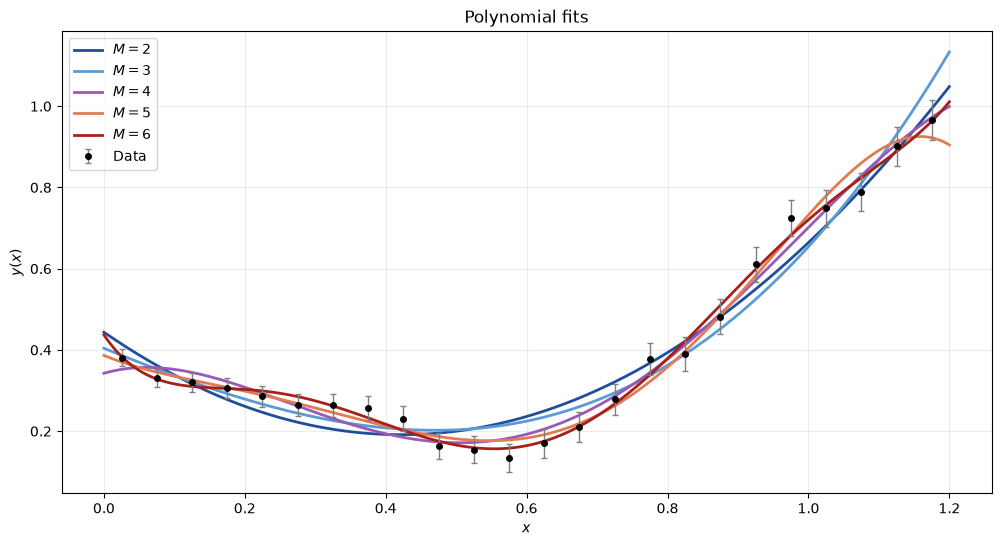

In [4]:
def polynomial(a, x):
    "Polynomial with coefficients a = (a_0, ..., a_M) evaluated at x"
    return sum(a[k] * x**k for k in range(a.size))


M_plot = [2, 3, 4, 5, 6]
x_fine = np.linspace(0, 1.2, 1000)
colors = ["#1f4e9c", "#5b9bd5", "#9b59b6", "#e07b54", "#a8201a"]

fig, ax = plt.subplots(figsize=(12, 6))
ax.errorbar(x, y, yerr=sigma, fmt="o", ms=4, capsize=2, color="black", ecolor="gray", elinewidth=1, label="Data", zorder=3)
for M, c in zip(M_plot, colors):
    r = results[M]
    ax.plot(x_fine, polynomial(r["a"], x_fine), color=c, lw=2, label=rf"$M = {M}$")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y(x)$")
ax.set_title("Polynomial fits")
ax.legend()
ax.grid(alpha=0.3, color="silver")
fig.savefig("images/fits.pdf", bbox_inches="tight")
plt.show()


### High order polynomials

The polynomials of order $M = 6, 7, 8$ are compared in the figure below.
In the range of the data the three curves are practically indistinguishable, consistently with the very small decrease of $\chi^2_{min}$ ($\Delta\chi^2 < 1$) obtained by adding the corresponding parameters.
The curves differ only at the edges of the interval, shown in the two zoomed panels: at the measurement points the differences between them are at most about half of the uncertainty $\sigma_i$, and they become larger only outside the range of the data ($x < 0.025$ and $x > 1.175$), where the polynomials are not constrained by any measurement.

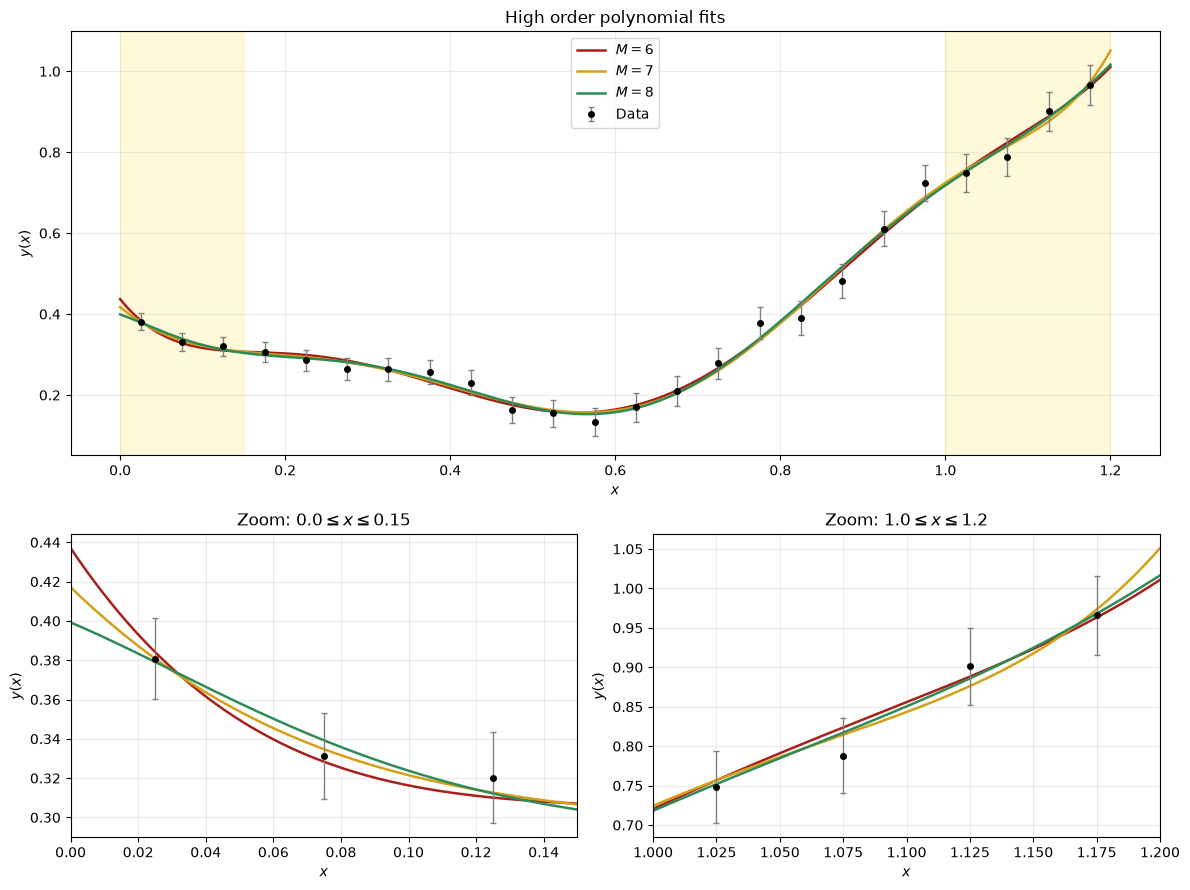

In [5]:
M_high = [6, 7, 8]
colors_high = ["#a8201a", "#d4a017", "#2e8b57"]
zooms = [(0.0, 0.15), (1.0, 1.2)]

fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.4, 1])
ax_main = fig.add_subplot(gs[0, :])
ax_zoom = [fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]

for ax in [ax_main] + ax_zoom:
    ax.errorbar(x, y, yerr=sigma, fmt="o", ms=4, capsize=2, color="black", ecolor="gray", elinewidth=1, label="Data", zorder=3)
    for M, c in zip(M_high, colors_high):
        r = results[M]
        ax.plot(x_fine, polynomial(r["a"], x_fine), color=c, lw=1.8, label=rf"$M = {M}$")
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y(x)$")
    ax.grid(alpha=0.3, color="silver")

# Zoomed panels: y range adapted to the curves and to the data in the selected x range
for ax, (x_lo, x_hi) in zip(ax_zoom, zooms):
    in_range = (x_fine >= x_lo) & (x_fine <= x_hi)
    points = (x >= x_lo) & (x <= x_hi)
    curves = np.concatenate([polynomial(results[M]["a"], x_fine[in_range]) for M in M_high])
    y_lo = min(curves.min(), (y - sigma)[points].min())
    y_hi = max(curves.max(), (y + sigma)[points].max())
    pad = 0.05 * (y_hi - y_lo)
    ax.set_xlim(x_lo, x_hi)
    ax.set_ylim(y_lo - pad, y_hi + pad)
    ax.set_title(rf"Zoom: ${x_lo} \leq x \leq {x_hi}$")
    ax_main.axvspan(x_lo, x_hi, color="gold", alpha=0.15)     # zoomed region in the main panel

ax_main.set_title("High order polynomial fits")
ax_main.legend()
fig.tight_layout()
fig.savefig("images/fits_high_order.pdf", bbox_inches="tight")
plt.show()
